In [1]:
import pandas as pd
import glob
import plotly.express as px

In [6]:
files = sorted(glob.glob("trendsset1_season/*.csv"))
print(len(files))
files

6


['trendsset1_season/2020.csv',
 'trendsset1_season/2021.csv',
 'trendsset1_season/2022.csv',
 'trendsset1_season/2023.csv',
 'trendsset1_season/2024.csv',
 'trendsset1_season/2025.csv']

In [3]:
def prepare_trends(file_name, keep_terms=None):
    df = pd.read_csv(file_name)
    df = df.rename(columns={"Time": "date"})
    df["date"] = pd.to_datetime(df["date"])

    long = df.melt(id_vars="date", var_name="term", value_name="interest")
    long["interest"] = pd.to_numeric(long["interest"].replace("<1", 0))

    if keep_terms is not None:                       # optional: keep only some terms
        long = long[long["term"].isin(keep_terms)].copy()

    season = long.loc[long["date"].dt.month == 12, "date"].dt.year.iloc[0]
    long["season"] = season
    christmas = pd.Timestamp(f"{season}-12-25")
    long["weeks_before_christmas"] = ((christmas - long["date"]).dt.days / 7).round()

    return long

In [7]:
season_curve = pd.concat(
    [prepare_trends(f, keep_terms=["christmas"]) for f in files],
    ignore_index=True
)
season_curve["season"].value_counts().sort_index()

season
2020    18
2021    18
2022    18
2023    19
2024    19
2025    18
Name: count, dtype: int64

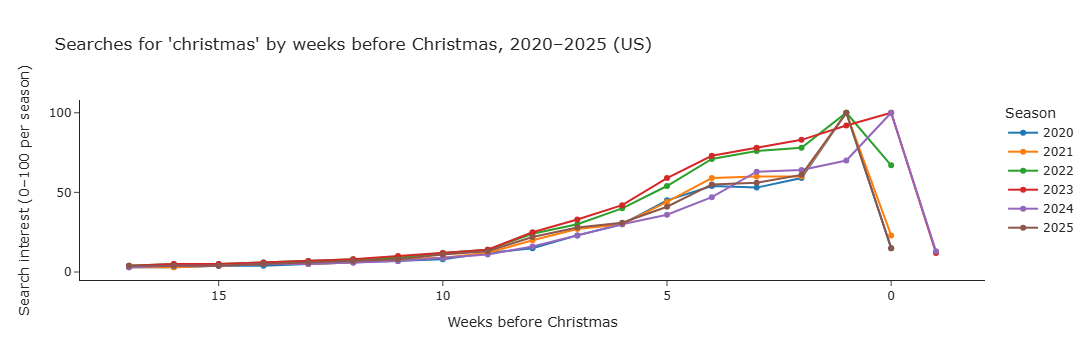

In [ ]:
fig = px.line(season_curve, x="weeks_before_christmas", y="interest", color="season",
              markers=True,
              title="Searches for 'christmas' by weeks before Christmas, 2020–2025 (US)",
              labels={"weeks_before_christmas": "Weeks before Christmas",
                      "interest": "Search interest (0–100 per season)", "season": "Season"},
              template="simple_white")
fig.update_xaxes(autorange="reversed")
fig.show()

In [ ]:
def timing(group, factor=2):
    group = group.sort_values("date").reset_index(drop=True)
    baseline = group.loc[group["date"].dt.month == 9, "interest"].mean()
    peak_pos = group["interest"].idxmax()

    above = group["interest"] >= factor * baseline
    start_pos = None
    for i in range(peak_pos + 1):
        if above.iloc[i:peak_pos + 1].all():
            start_pos = i
            break

    if start_pos is None:
        start_week, start_before = pd.NaT, float("nan")
    else:
        start_week = group.loc[start_pos, "date"]
        start_before = group.loc[start_pos, "weeks_before_christmas"]

    return pd.Series({
        "baseline": round(baseline, 1),
        "start_week": start_week,
        "start_weeks_before": start_before,
        "peak_week": group.loc[peak_pos, "date"],
        "peak_weeks_before": group.loc[peak_pos, "weeks_before_christmas"],
    })

season_timing = season_curve.groupby("season").apply(timing).reset_index()
season_timing

,season,baseline,start_week,start_weeks_before,peak_week,peak_weeks_before
0,2020,4.0,2020-10-18,10.0,2020-12-20,1.0
1,2021,4.2,2021-10-17,10.0,2021-12-19,1.0
2,2022,5.8,2022-10-16,10.0,2022-12-18,1.0
3,2023,5.8,2023-10-15,10.0,2023-12-24,0.0
4,2024,4.8,2024-10-20,9.0,2024-12-22,0.0
5,2025,4.8,2025-10-19,10.0,2025-12-21,1.0


In [ ]:
season_timing[["start_weeks_before", "peak_weeks_before"]].mean().round(1)

start_weeks_before    9.8
peak_weeks_before     0.7
dtype: float64

In [ ]:
import requests, pandas as pd

def wiki_views(article, start="20200901", end="20251231"):
    url = (f"https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
           f"en.wikipedia/all-access/user/{article}/daily/{start}/{end}")
    headers = {"User-Agent": "IronFact student project (your_email@example.com)"}
    data = requests.get(url, headers=headers).json()["items"]
    df = pd.DataFrame(data)[["timestamp", "views"]]
    df["date"] = pd.to_datetime(df["timestamp"], format="%Y%m%d%H")
    df["article"] = article
    return df[["date", "article", "views"]]

xmas = wiki_views("Christmas")

In [ ]:
xmas

,date,article,views
0,2020-09-01,Christmas,2927
1,2020-09-02,Christmas,2151
2,2020-09-03,Christmas,2002
3,2020-09-04,Christmas,1961
4,2020-09-05,Christmas,1856
...,...,...,...
1943,2025-12-27,Christmas,13446
1944,2025-12-28,Christmas,9588
1945,2025-12-29,Christmas,8264
1946,2025-12-30,Christmas,6970


In [ ]:
xmas.head()
xmas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1948 entries, 0 to 1947
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     1948 non-null   datetime64[us]
 1   article  1948 non-null   str           
 2   views    1948 non-null   int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 63.1 KB


In [ ]:
wiki = xmas.copy()

In [ ]:
weekly = (wiki.set_index("date")
              .groupby("article")["views"]
              .resample("W-SUN", label="left", closed="left")
              .sum()
              .reset_index())

In [ ]:
weekly = weekly[weekly["date"].dt.month.isin([9, 10, 11, 12])].copy()

weekly["season"] = weekly["date"].dt.year
christmas = pd.to_datetime(weekly["season"].astype(str) + "-12-25")
weekly["weeks_before_christmas"] = ((christmas - weekly["date"]).dt.days / 7).round()

In [ ]:
weekly["interest"] = (weekly["views"] /
                      weekly.groupby(["article", "season"])["views"].transform("max") * 100).round()

In [ ]:
wiki_timing = weekly.groupby(["article", "season"]).apply(timing).reset_index()
wiki_timing.groupby("article")[["start_weeks_before", "peak_weeks_before"]].mean().round(1)

,start_weeks_before,peak_weeks_before
article,,
Christmas,7.5,0.7


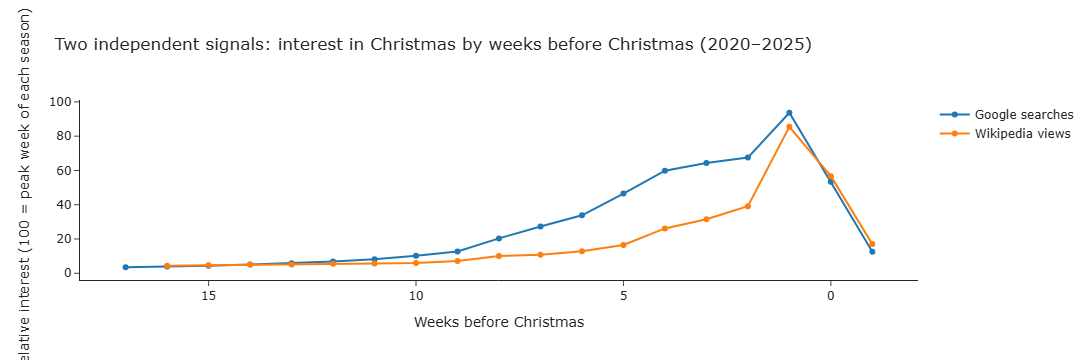

In [ ]:
compare = pd.concat([
    season_curve.assign(source="Google searches")[["weeks_before_christmas", "interest", "source"]],
    weekly[weekly["article"] == "Christmas"].assign(source="Wikipedia views")[["weeks_before_christmas", "interest", "source"]],
])
avg = compare.groupby(["source", "weeks_before_christmas"])["interest"].mean().reset_index()

fig = px.line(avg, x="weeks_before_christmas", y="interest", color="source", markers=True,
              title="Two independent signals: interest in Christmas by weeks before Christmas (2020–2025)",
              labels={"weeks_before_christmas": "Weeks before Christmas",
                      "interest": "Relative interest (100 = peak week of each season)", "source": ""},
              template="simple_white")
fig.update_xaxes(autorange="reversed")
fig.show()

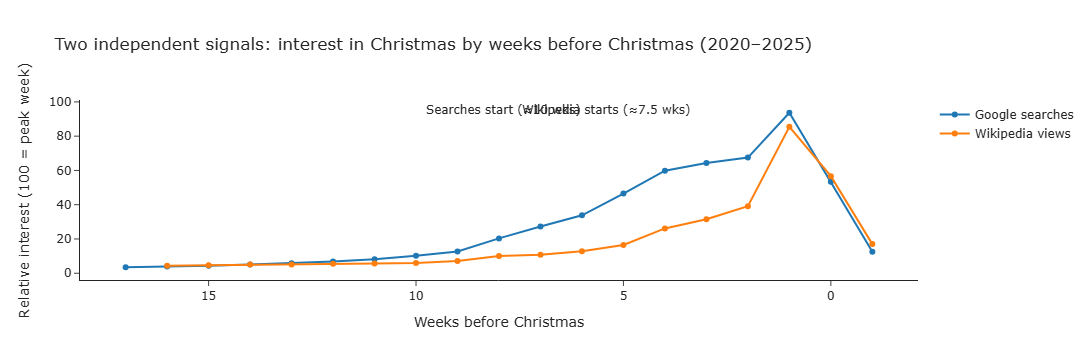

In [ ]:
fig.update_layout(margin=dict(l=80))
fig.update_yaxes(title_text="Relative interest (100 = peak week)")
fig.add_vline(x=9.8, line_dash="dot", line_color="#1f77b4", annotation_text="Searches start (≈10 wks)")
fig.add_vline(x=7.5, line_dash="dot", line_color="#ff7f0e", annotation_text="Wikipedia starts (≈7.5 wks)")

In [ ]:
season_timing.to_csv("timing_google_christmas.csv", index=False)

In [ ]:
wiki_timing.to_csv("timing_wiki.csv", index=False)